# Chapter 18: Strong directions first

Checks [chapter 18](../../book/18-strong-directions-first.md), the statement of `spectral_bias` in
`SpectralBias.lean`. The model is **linear in its weights**: `prediction = features @ weights`, trained by
full-batch gradient descent on half the squared error, so one step is
`weights <- weights - learning_rate * features.T @ residual` and the kernel is `kernel = features @ features.T`.
A *strength* is an eigenvalue of the kernel, a *direction* is an eigenvector, `rate = learning_rate * strength`.
Everything is NumPy in float64, seeded. These are measurements on examples, not proofs: the proofs are in
`SpectralBias.lean`. Run every cell, top to bottom. A failed check stops the notebook.

What the theorem says, and so what each experiment checks and nothing wider: along a direction that the kernel
only stretches, the share of the start error left after `step_count` steps is exactly `(1 - rate) ^ step_count`,
and when `rate <= 1` it lies between `1 - step_count * rate` and `exp(-step_count * rate)`.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE, DATA
import matplotlib.pyplot as plt
import seaborn as sns

use_style()
SEED = 18
EXACT_TOLERANCE = 1e-9     # float64 error after a few hundred steps is about 1e-14; this leaves a wide margin


def run_gradient_descent(features, labels, start_weights, learning_rate, step_count):
    # Real full-batch gradient descent, not the formula. Row `step` holds the residual after `step` steps.
    weights = start_weights.copy()
    residuals = []
    for step in range(step_count + 1):
        residual = features @ weights - labels
        residuals.append(residual)
        weights = weights - learning_rate * features.T @ residual
    return np.array(residuals)


def get_stretch_gap(kernel, direction):
    # How far `direction` is from being only stretched by `kernel`: the size of the part of
    # kernel @ direction that is not along direction, over the size of kernel @ direction.
    image = kernel @ direction
    strength = (direction @ image) / (direction @ direction)
    return np.linalg.norm(image - strength * direction) / np.linalg.norm(image), strength

## Experiment 1: each direction decays by its own factor, between the two bounds

**Model.** 12 data points, 8 weights, a random feature matrix whose columns have sizes from 1 down to 0.2, so the
strengths are spread over about a factor of 25 or more. The kernel has rank 8 in 12 dimensions, so four strengths are
zero. The learning rate is `0.9 / strongest_strength`, so every `rate <= 1` and the theorem's hypothesis holds. Random
labels, start weights zero.

**Prediction, stated before the run.** For every direction `direction` (an eigenvector of the kernel), the measured
component `inner(direction, residual_after_step)` equals `(1 - rate) ^ step * start_component` to within
`1e-9`, and its size lies between `(1 - step * rate) * |start_component|` and
`exp(-step * rate) * |start_component|`. A direction of strength zero keeps its start value. **Count against the
claim:** any direction and step where the measured component differs from the formula by more than `1e-9`,
or leaves the band by more than `1e-9`.

**Control.** Start the error along a coordinate axis, which is not a direction the kernel only stretches. The
claim says its component has no single factor. The measure: the largest gap between the log of the component and
the best straight line in the step (a single factor is a straight line, gap 0). The same measure on an eigen-direction
is the baseline. The control counts against the claim if its gap is not far above the baseline: the threshold is
`1e-3` nats, and the baseline is expected below `1e-9` (steps where the component is below `1e-5` of its start are left out, as float64 noise then matters).

In [2]:
generator = np.random.default_rng(SEED)
NUM_DATA, NUM_WEIGHTS, STEP_COUNT = 12, 8, 400

column_sizes = np.logspace(0, np.log10(0.2), NUM_WEIGHTS)
features = generator.standard_normal((NUM_DATA, NUM_WEIGHTS)) * column_sizes
labels = generator.standard_normal(NUM_DATA)
start_weights = np.zeros(NUM_WEIGHTS)

kernel = features @ features.T
strengths, directions = np.linalg.eigh(kernel)            # ascending; column i of `directions` is a direction
order = np.argsort(strengths)[::-1]
strengths, directions = strengths[order], directions[:, order]
learning_rate = 0.9 / strengths[0]
rates = learning_rate * strengths

residuals = run_gradient_descent(features, labels, start_weights, learning_rate, STEP_COUNT)
steps = np.arange(STEP_COUNT + 1)
components = residuals @ directions                       # row = step, column = direction
start_components = components[0]

formula = (1 - rates) ** steps[:, None] * start_components
lower = (1 - steps[:, None] * rates) * np.abs(start_components)
upper = np.exp(-steps[:, None] * rates) * np.abs(start_components)

worst_formula_gap = np.abs(components - formula).max()
worst_below_lower = np.maximum(lower - np.abs(components), 0).max()
worst_above_upper = np.maximum(np.abs(components) - upper, 0).max()
zero_directions = strengths < 1e-10
print("strengths:", np.array2string(strengths, precision=4))
print("rates    :", np.array2string(rates, precision=5))
print("smallest |start component| over the nonzero directions:", np.abs(start_components[~zero_directions]).min())

report("every start component of a nonzero direction is large enough for the check to mean something",
       np.abs(start_components[~zero_directions]).min() > 1e-2,
       f"smallest {np.abs(start_components[~zero_directions]).min():.3f}")
report("the component along each direction is (1 - rate)^step times its start, over 400 steps",
       worst_formula_gap < EXACT_TOLERANCE, f"largest gap {worst_formula_gap:.1e}")
report("and it lies between the two bounds of spectral_bias at every step",
       worst_below_lower < EXACT_TOLERANCE and worst_above_upper < EXACT_TOLERANCE,
       f"below lower by at most {worst_below_lower:.1e}, above upper by at most {worst_above_upper:.1e}")
report("the directions of strength zero never move",
       np.abs(components[:, zero_directions] - start_components[zero_directions]).max() < EXACT_TOLERANCE,
       f"{int(zero_directions.sum())} directions of strength below 1e-10")

# The total error is the sum of the pieces, each on its own clock.
total_loss = 0.5 * (residuals ** 2).sum(axis=1)
total_from_pieces = 0.5 * ((1 - rates) ** steps[:, None] * start_components) ** 2
report("half the squared error equals the sum over directions of the squared pieces",
       np.abs(total_loss - total_from_pieces.sum(axis=1)).max() < 1e-9 * total_loss[0],
       f"largest gap {np.abs(total_loss - total_from_pieces.sum(axis=1)).max():.1e} against start loss {total_loss[0]:.2f}")

strengths: [ 1.2847e+01  3.8188e+00  2.8031e+00  2.5093e+00  1.1327e+00  7.2079e-01
  1.0510e-01  4.2531e-02  6.1923e-16  1.1891e-16 -9.6577e-17 -3.8523e-16]
rates    : [ 9.00000e-01  2.67537e-01  1.96377e-01  1.75794e-01  7.93534e-02
  5.04968e-02  7.36280e-03  2.97962e-03  4.33819e-17  8.33035e-18
 -6.76592e-18 -2.69884e-17]
smallest |start component| over the nonzero directions: 0.03650604653619542
[PASS] every start component of a nonzero direction is large enough for the check to mean something  (smallest 0.037)
[PASS] the component along each direction is (1 - rate)^step times its start, over 400 steps  (largest gap 8.2e-15)
[PASS] and it lies between the two bounds of spectral_bias at every step  (below lower by at most 3.8e-15, above upper by at most 1.9e-14)
[PASS] the directions of strength zero never move  (4 directions of strength below 1e-10)
[PASS] half the squared error equals the sum over directions of the squared pieces  (largest gap 1.0e-14 against start loss 4.13)


True

In [3]:
# Control A: a start error that is a single eigen-direction stays on it; a coordinate axis does not.
def get_log_line_gap(component):
    # Largest gap between log(component) and its best straight line in the step. Zero for one factor.
    sizes = np.abs(component)
    keep = sizes > 1e-5 * sizes[0]
    log_sizes = np.log(sizes[keep])
    kept_steps = np.arange(len(component))[keep]
    slope, intercept = np.polyfit(kept_steps, log_sizes, 1)
    return np.abs(log_sizes - (slope * kept_steps + intercept)).max()


strong_index = 1
start_on_direction = directions[:, strong_index]
start_on_axis = np.zeros(NUM_DATA)
start_on_axis[0] = 1.0
control_rows = {}
for name, start_error in (("eigen-direction", start_on_direction), ("coordinate axis", start_on_axis)):
    control_labels = -start_error                   # start weights are zero, so the start residual is start_error
    control_residuals = run_gradient_descent(features, control_labels, start_weights, learning_rate, 60)
    if name == "eigen-direction":
        component = control_residuals @ start_on_direction
        off_direction = np.linalg.norm(control_residuals - component[:, None] * start_on_direction, axis=1).max()
    else:
        component = control_residuals[:, 0]
        off_direction = np.linalg.norm(control_residuals - component[:, None] * start_on_axis, axis=1).max()
    ratios = component[1:] / component[:-1]
    control_rows[name] = {"gap": get_log_line_gap(component), "off": off_direction,
                          "ratio_spread": ratios.max() - ratios.min()}
    print(f"{name:16s}: log-line gap {control_rows[name]['gap']:.2e}, step-to-step ratio spread "
          f"{control_rows[name]['ratio_spread']:.2e}, largest size off the starting line {off_direction:.2e}")

report("an eigen-direction stays on its line and has one factor (the baseline)",
       control_rows["eigen-direction"]["gap"] < 1e-9 and control_rows["eigen-direction"]["off"] < 1e-9,
       f"gap {control_rows['eigen-direction']['gap']:.1e}, off the line {control_rows['eigen-direction']['off']:.1e}")
report("control: a coordinate axis leaves its line and has no single factor",
       control_rows["coordinate axis"]["gap"] > 1e-3 and control_rows["coordinate axis"]["off"] > 1e-2,
       f"gap {control_rows['coordinate axis']['gap']:.2e} nats, off the line {control_rows['coordinate axis']['off']:.2f}")

eigen-direction : log-line gap 2.88e-12, step-to-step ratio spread 6.23e-09, largest size off the starting line 5.04e-16
coordinate axis : log-line gap 3.84e-01, step-to-step ratio spread 1.52e-01, largest size off the starting line 4.25e-01
[PASS] an eigen-direction stays on its line and has one factor (the baseline)  (gap 2.9e-12, off the line 5.0e-16)
[PASS] control: a coordinate axis leaves its line and has no single factor  (gap 3.84e-01 nats, off the line 0.42)


True

### Figure: the decay per direction with both bounds

Five directions of the model above, from the strongest to the weakest nonzero one. Solid: the measured share of
the start error left (`|component| / |start component|`) from real gradient descent. Dashed green: the two bounds
of `spectral_bias` around it. The lower bound is drawn only where it is positive. Dots mark one clock,
`step = 1 / rate`. Both axes are on a log scale, and the lower bound is not drawn once it is below the bottom of the axis. The picture is a measurement of the theorem's own setting.

strength 12.8466, clock 1 / rate = 1.1 steps, first step with share below 1e-4: 4, share at step 400: 0.000
strength 3.8188, clock 1 / rate = 3.7 steps, first step with share below 1e-4: 30, share at step 400: 0.000
strength 2.5093, clock 1 / rate = 5.7 steps, first step with share below 1e-4: 48, share at step 400: 0.000
strength 0.7208, clock 1 / rate = 19.8 steps, first step with share below 1e-4: 178, share at step 400: 0.000
strength 0.0425, clock 1 / rate = 335.6 steps, first step with share below 1e-4: none within 400, share at step 400: 0.303


wrote book/figures/18-two-bounds.png


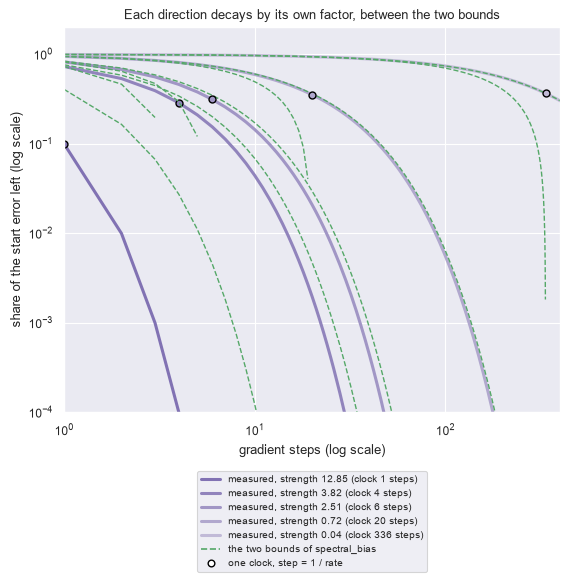

In [4]:
shown = [0, 1, 3, 5, 7]
shades = sns.light_palette(MODEL, n_colors=len(shown) + 3)[3:][::-1]
figure, axis = plt.subplots(figsize=(6.4, 5.0))
for shade, index in zip(shades, shown):
    share = np.abs(components[:, index]) / abs(start_components[index])
    lower_share = 1 - steps * rates[index]
    upper_share = np.exp(-steps * rates[index])
    clock = int(round(1 / rates[index]))
    axis.plot(steps[1:], share[1:], color=shade, linewidth=2.2,
              label=f"measured, strength {strengths[index]:.2f} (clock {clock} steps)")
    keep_lower = lower_share > 1e-4
    keep_lower[0] = False
    axis.plot(steps[keep_lower], lower_share[keep_lower], color=BOUND, linestyle="--", linewidth=1.0)
    axis.plot(steps[1:], upper_share[1:], color=BOUND, linestyle="--", linewidth=1.0)
    if clock <= STEP_COUNT:
        axis.plot([clock], [share[clock]], marker="o", color=shade, markeredgecolor="black", markersize=5)
axis.plot([], [], color=BOUND, linestyle="--", label="the two bounds of spectral_bias")
axis.plot([], [], marker="o", color="white", markeredgecolor="black", linestyle="", label="one clock, step = 1 / rate")
axis.set_yscale("log")
axis.set_ylim(1e-4, 2)
axis.set_xscale("log")
axis.set_xlim(1, STEP_COUNT)
axis.set_xlabel("gradient steps (log scale)")
axis.set_ylabel("share of the start error left (log scale)")
axis.set_title("Each direction decays by its own factor, between the two bounds")
axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=7)
for shade, index in zip(shades, shown):
    share = np.abs(components[:, index]) / abs(start_components[index])
    below = np.flatnonzero(share < 1e-4)
    print(f"strength {strengths[index]:.4f}, clock 1 / rate = {1 / rates[index]:.1f} steps, "
          f"first step with share below 1e-4: {int(below[0]) if len(below) else 'none within 400'}, "
          f"share at step {STEP_COUNT}: {share[STEP_COUNT]:.3f}")
save_figure(figure, "18-two-bounds")
plt.show()

## Experiment 2: where the bounds are tight and where they are loose

Same run as experiment 1. The share left is `(1 - rate) ^ step`. Taking logs, `-ln(1 - rate) = rate + rate^2 / 2 +
rate^3 / 3 + ...`, which is at least `rate + rate^2 / 2` and at most `rate + rate^2 / (2 (1 - rate))`. So the upper
bound divided by the true share is `exp(step * (-rate - ln(1 - rate)))`, and the log of it lies between
`step * rate^2 / 2` and `step * rate^2 / (2 (1 - rate))`.

**Prediction, stated before the run.** (a) For every direction with `0 < rate < 1` and every step where the share is
still above `1e-6`, the measured `log(upper bound / share)` lies between those two numbers (tolerance `1e-6` nats).
That is a derived formula, and the check can fail if the derivation is wrong. (b) Once `step * rate >= 1` the lower
bound is `<= 0`, so it says nothing. That is algebra, not a measurement: it is printed as "by construction, cannot fail"
and is not counted as a check.
**Count against (a):** a measured point outside the band.

In [5]:
nonzero = np.flatnonzero(rates > 1e-6)
share_all = np.abs(components) / np.abs(start_components)
outside = 0
points = 0
for index in nonzero:
    rate = rates[index]
    meaningful = share_all[:, index] > 1e-6
    log_ratio = (-steps * rate)[meaningful] - np.log(share_all[meaningful, index])        # log(upper / share), upper = exp(-step*rate)
    low = steps[meaningful] * rate ** 2 / 2
    high = steps[meaningful] * rate ** 2 / (2 * (1 - rate))
    outside += int(((log_ratio < low - 1e-6) | (log_ratio > high + 1e-6)).sum())
    points += int(meaningful.sum())

report("log(upper bound / share) lies between step*rate^2/2 and step*rate^2/(2(1-rate)) at every measured point",
       outside == 0, f"{points} points over {len(nonzero)} directions, {outside} outside")

vacuous_points = 0
vacuous_wrong = 0
for index in nonzero:
    past_clock = steps * rates[index] >= 1
    vacuous_points += int(past_clock.sum())
    vacuous_wrong += int((past_clock & (lower[:, index] > 1e-12)).sum())
print(f"[by construction, cannot fail] once step * rate >= 1 the lower bound 1 - step * rate is not positive "
      f"({vacuous_points} points, {vacuous_wrong} with a positive lower bound); this is algebra, not evidence")

print()
print("lower / share is max(1 - p, 0) / share, so it is 0 from p = 1 on by construction.")
print("at step * rate = p (step rounded), over the directions with rate > 1e-6 and share > 1e-6:")
print(f"{'p':>5} {'directions':>10} {'lower / share (median)':>24} {'upper / share (median)':>24} {'upper / share (largest)':>25}")
table = []
for target in (0.1, 0.5, 1.0, 2.0, 5.0):
    lower_ratios, upper_ratios = [], []
    for index in nonzero:
        step = int(round(target / rates[index]))
        if step <= STEP_COUNT and share_all[step, index] > 1e-6:
            lower_ratios.append(max(1 - step * rates[index], 0) / share_all[step, index])
            upper_ratios.append(np.exp(-step * rates[index]) / share_all[step, index])
    table.append((target, len(lower_ratios), np.median(lower_ratios), np.median(upper_ratios), np.max(upper_ratios)))
    print(f"{target:5.1f} {len(lower_ratios):10d} {table[-1][2]:24.3f} {table[-1][3]:24.3f} {table[-1][4]:25.3f}")

[PASS] log(upper bound / share) lies between step*rate^2/2 and step*rate^2/(2(1-rate)) at every measured point  (1424 points over 8 directions, 0 outside)
[by construction, cannot fail] once step * rate >= 1 the lower bound 1 - step * rate is not positive (2685 points, 0 with a positive lower bound); this is algebra, not evidence

lower / share is max(1 - p, 0) / share, so it is 0 from p = 1 on by construction.
at step * rate = p (step rounded), over the directions with rate > 1e-6 and share > 1e-6:
    p directions   lower / share (median)   upper / share (median)   upper / share (largest)
  0.1          8                    1.000                    1.002                     1.022
  0.5          8                    0.838                    1.037                     4.066
  1.0          8                    0.000                    1.078                     4.066
  2.0          7                    0.000                    1.213                    16.530
  5.0          5              

## Experiment 3: the Fourier case, where the sampled cosines and sines are the directions

**Model.** 16 inputs evenly spaced over one period, `input = 2 pi i / 16`. Features `amplitude_k * cos(k input)` and
`amplitude_k * sin(k input)` for `k = 1 .. 7` (7 is below half of 16), with `amplitude_k = 1 / k`. The model is
linear in the 14 weights, which are the coefficients of those fixed features. The kernel is
`kernel[i, j] = sum_k amplitude_k^2 cos(k (input_i - input_j))`, which depends only on the gap between two inputs.

**Prediction, stated before the run.** The sampled `cos(k input)` and `sin(k input)` are eigen-directions of the
kernel matrix, with strength `(number_of_inputs / 2) * amplitude_k^2 = 8 / k^2`. The measure of how far a direction
is from being only stretched is `get_stretch_gap`: `0` for an eigen-direction, and about `1e-15` in float64.
The check can fail if the strengths are off, or the gap is not tiny, for any of the 14 directions. Gradient
descent from zero weights on random labels, learning rate `0.9 / strongest_strength`, then follows
`(1 - rate)^step` on each: the step at which half of the start error has gone should be the smallest whole number
with `(1 - rate)^step <= 1/2`, strictly later for each higher frequency (the amplitudes fall with frequency).

**Control.** Move each input by a random amount of up to `0.3` of the spacing, seeded, so the inputs are no longer
evenly spaced. The sampled cosines and sines at the new inputs should no longer be eigen-directions: the gap must
be far above `1e-15`. The control counts against the claim if some gap stays below `1e-3`.

In [6]:
NUM_INPUTS, MAX_FREQUENCY = 16, 7
frequencies = np.arange(1, MAX_FREQUENCY + 1)
amplitudes = 1.0 / frequencies


def make_fourier_features(inputs):
    angles = np.outer(inputs, frequencies)
    return np.concatenate([amplitudes * np.cos(angles), amplitudes * np.sin(angles)], axis=1)


def make_sampled_directions(inputs):
    angles = np.outer(inputs, frequencies)
    return np.cos(angles), np.sin(angles)             # column k - 1 holds the frequency k, one value per input


even_inputs = 2 * np.pi * np.arange(NUM_INPUTS) / NUM_INPUTS
spacing = 2 * np.pi / NUM_INPUTS
fourier_generator = np.random.default_rng(SEED + 1)
uneven_inputs = even_inputs + fourier_generator.uniform(-0.3, 0.3, NUM_INPUTS) * spacing
predicted_strengths = (NUM_INPUTS / 2) * amplitudes ** 2

summary = {}
for name, inputs in (("evenly spaced", even_inputs), ("unevenly spaced (control)", uneven_inputs)):
    fourier_features = make_fourier_features(inputs)
    fourier_kernel = fourier_features @ fourier_features.T
    cosines, sines = make_sampled_directions(inputs)
    gaps, strength_errors = [], []
    for column in range(MAX_FREQUENCY):
        for sampled in (cosines[:, column], sines[:, column]):
            gap, strength = get_stretch_gap(fourier_kernel, sampled)
            gaps.append(gap)
            strength_errors.append(abs(strength - predicted_strengths[column]) / predicted_strengths[column])
    summary[name] = {"gaps": np.array(gaps), "strength_errors": np.array(strength_errors), "kernel": fourier_kernel}
    print(f"{name:26s}: gap over 14 directions, smallest {min(gaps):.1e}, largest {max(gaps):.1e}; "
          f"largest relative error of the predicted strength {max(strength_errors):.1e}")

even = summary["evenly spaced"]
control = summary["unevenly spaced (control)"]
report("evenly spaced: the 14 sampled cosines and sines are only stretched by the kernel",
       even["gaps"].max() < 1e-12, f"largest gap {even['gaps'].max():.1e}")
report("evenly spaced: their strength is (number_of_inputs / 2) * amplitude^2",
       even["strength_errors"].max() < 1e-12, f"largest relative error {even['strength_errors'].max():.1e}")
sorted_strengths = np.sort(np.linalg.eigvalsh(even["kernel"]))[::-1]
expected_sorted = np.sort(np.concatenate([predicted_strengths, predicted_strengths, [0.0, 0.0]]))[::-1]
report("evenly spaced: the kernel has no other strengths (two copies of each, and two zeros)",
       np.abs(sorted_strengths - expected_sorted).max() < 1e-12,
       f"largest difference of the sorted strengths {np.abs(sorted_strengths - expected_sorted).max():.1e}")
report("control, unevenly spaced: none of the sampled cosines and sines is only stretched",
       control["gaps"].min() > 1e-3, f"smallest gap {control['gaps'].min():.1e}, largest {control['gaps'].max():.1e}")

evenly spaced             : gap over 14 directions, smallest 6.7e-17, largest 3.1e-14; largest relative error of the predicted strength 2.0e-15
unevenly spaced (control) : gap over 14 directions, smallest 2.8e-02, largest 9.4e-01; largest relative error of the predicted strength 1.8e+00
[PASS] evenly spaced: the 14 sampled cosines and sines are only stretched by the kernel  (largest gap 3.1e-14)
[PASS] evenly spaced: their strength is (number_of_inputs / 2) * amplitude^2  (largest relative error 2.0e-15)
[PASS] evenly spaced: the kernel has no other strengths (two copies of each, and two zeros)  (largest difference of the sorted strengths 3.6e-15)
[PASS] control, unevenly spaced: none of the sampled cosines and sines is only stretched  (smallest gap 2.8e-02, largest 9.4e-01)


True

In [7]:
# Train on the evenly spaced inputs and follow the pieces along the cosines and sines.
fourier_features = make_fourier_features(even_inputs)
cosines, sines = make_sampled_directions(even_inputs)
fourier_labels = np.random.default_rng(SEED + 2).standard_normal(NUM_INPUTS)
fourier_learning_rate = 0.9 / predicted_strengths[0]
FOURIER_STEP_COUNT = 200
fourier_residuals = run_gradient_descent(fourier_features, fourier_labels, np.zeros(2 * MAX_FREQUENCY),
                                         fourier_learning_rate, FOURIER_STEP_COUNT)
fourier_steps = np.arange(FOURIER_STEP_COUNT + 1)
fourier_rates = fourier_learning_rate * predicted_strengths
worst_gap = 0.0
half_steps_measured, half_steps_formula = [], []
for column in range(MAX_FREQUENCY):
    for sampled in (cosines[:, column], sines[:, column]):
        unit = sampled / np.linalg.norm(sampled)
        component = fourier_residuals @ unit
        worst_gap = max(worst_gap, np.abs(component - (1 - fourier_rates[column]) ** fourier_steps * component[0]).max())
        half_steps_measured.append(int(np.argmax(np.abs(component) <= 0.5 * abs(component[0]))))
    half_steps_formula.append(int(np.ceil(np.log(0.5) / np.log(1 - fourier_rates[column]))))
half_steps_measured = np.array(half_steps_measured).reshape(MAX_FREQUENCY, 2)
cosine_half, sine_half = half_steps_measured[:, 0], half_steps_measured[:, 1]
print("frequency       :", frequencies)
print("strength        :", np.array2string(predicted_strengths, precision=3))
print("half-error step, measured on cosine:", cosine_half)
print("half-error step, measured on sine  :", sine_half)
print("half-error step, from (1-rate)^step:", np.array(half_steps_formula))

report("real gradient descent follows (1 - rate)^step along each sampled cosine and sine",
       worst_gap < EXACT_TOLERANCE, f"largest gap {worst_gap:.1e} of the start component")
report("the step at which half the error has gone matches the formula, for cosines and sines",
       np.array_equal(cosine_half, half_steps_formula) and np.array_equal(sine_half, half_steps_formula),
       f"steps {half_steps_formula}")
report("each higher frequency takes strictly more steps, measured on cosines and on sines (amplitudes fall like 1/k)",
       bool(np.all(np.diff(cosine_half) > 0) and np.all(np.diff(sine_half) > 0)), f"measured steps {list(cosine_half)}")

frequency       : [1 2 3 4 5 6 7]
strength        : [8.    2.    0.889 0.5   0.32  0.222 0.163]
half-error step, measured on cosine: [ 1  3  7 12 19 28 38]
half-error step, measured on sine  : [ 1  3  7 12 19 28 38]
half-error step, from (1-rate)^step: [ 1  3  7 12 19 28 38]
[PASS] real gradient descent follows (1 - rate)^step along each sampled cosine and sine  (largest gap 1.9e-15 of the start component)
[PASS] the step at which half the error has gone matches the formula, for cosines and sines  (steps [1, 3, 7, 12, 19, 28, 38])
[PASS] each higher frequency takes strictly more steps, measured on cosines and on sines (amplitudes fall like 1/k)  (measured steps [np.int64(1), np.int64(3), np.int64(7), np.int64(12), np.int64(19), np.int64(28), np.int64(38)])


True

### Figure: strength against frequency, and the order of learning

Left: the strength of the kernel along the sampled cosine of each frequency (the Rayleigh quotient of the direction;
for evenly spaced inputs it is the eigenvalue) against the prediction `(number_of_inputs / 2) * amplitude^2` (line),
and the same quantity for the unevenly spaced control (grey crosses, where it is no longer an eigenvalue). Right: the
step at which half of the start error is gone, measured from gradient descent on evenly spaced inputs (dots), against
the formula (line).

wrote book/figures/18-fourier-order.png


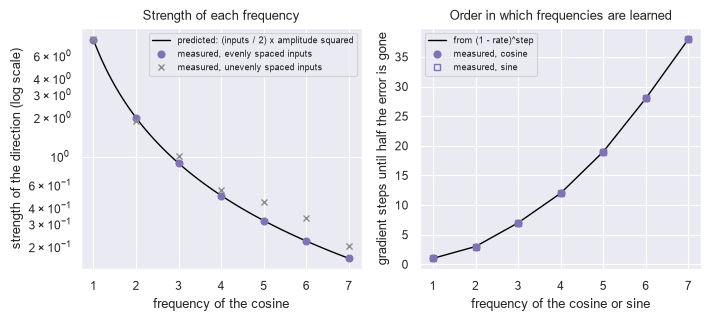

In [8]:
figure, (left, right) = plt.subplots(1, 2, figsize=(7.2, 3.3))
dense_frequencies = np.linspace(1, MAX_FREQUENCY, 100)
left.plot(dense_frequencies, (NUM_INPUTS / 2) / dense_frequencies ** 2, color=DATA, linewidth=1.0,
          label="predicted: (inputs / 2) x amplitude squared")
even_cosines, even_sines = make_sampled_directions(even_inputs)
uneven_cosines, uneven_sines = make_sampled_directions(uneven_inputs)
measured_even = [get_stretch_gap(even["kernel"], even_cosines[:, column])[1] for column in range(MAX_FREQUENCY)]
measured_uneven = [get_stretch_gap(control["kernel"], uneven_cosines[:, column])[1] for column in range(MAX_FREQUENCY)]
left.plot(frequencies, measured_even, "o", color=MODEL, label="measured, evenly spaced inputs")
left.plot(frequencies, measured_uneven, "x", color=BEFORE, label="measured, unevenly spaced inputs")
left.set_yscale("log")
left.set_xlabel("frequency of the cosine")
left.set_ylabel("strength of the direction (log scale)")
left.set_title("Strength of each frequency")
left.legend(fontsize=6.5, loc="upper right")

right.plot(frequencies, half_steps_formula, color=DATA, linewidth=1.0, label="from (1 - rate)^step")
right.plot(frequencies, cosine_half, "o", color=MODEL, label="measured, cosine")
right.plot(frequencies, sine_half, "s", color=MODEL, markerfacecolor="none", label="measured, sine")
right.set_xlabel("frequency of the cosine or sine")
right.set_ylabel("gradient steps until half the error is gone")
right.set_title("Order in which frequencies are learned")
right.legend(fontsize=6.5, loc="upper left")
figure.tight_layout()
save_figure(figure, "18-fourier-order")
plt.show()

## Experiment 4: a step too big for a direction

Same model as experiment 1, but the learning rate is `rate_target / strongest_strength`, so the strongest direction has
`rate = learning_rate * strength = rate_target`, for `rate_target` in 0.5, 1.0, 1.5, 2.0, 2.5. We follow the
strongest direction for 30 steps.

**Prediction, stated before the run.** The exact factor is still `1 - rate`, so the component is `(1 - rate)^step`
times its start, signed. For `rate > 1` the factor is negative: the component changes sign every step. Its size
shrinks if `rate < 2`, stays if `rate = 2`, grows if `rate > 2`. The hypothesis `rate_le_one` of `spectral_bias`
fails for `rate > 1`, so the bounds need not hold, and the prediction is that the *upper* bound is broken at every
step from step 1 (at `rate = 1.5` the share is `0.5^step`, which is larger than `exp(-1.5 step)`). The lower bound
`1 - step * rate` is negative from step 1, so it stays true and says nothing. **Count against:** any bound broken
for `rate <= 1`, or an upper bound held for `rate > 1`.

In [9]:
BIG_STEP_COUNT = 30
big_steps = np.arange(BIG_STEP_COUNT + 1)
big_rows = []
for rate_target in (0.5, 1.0, 1.5, 2.0, 2.5):
    big_learning_rate = rate_target / strengths[0]
    big_residuals = run_gradient_descent(features, labels, start_weights, big_learning_rate, BIG_STEP_COUNT)
    signed_share = (big_residuals @ directions[:, 0]) / start_components[0]
    exact = (1 - rate_target) ** big_steps
    exact_gap = np.abs(signed_share - exact).max() / max(1.0, np.abs(exact).max())
    upper_broken = int((np.abs(signed_share[1:]) > np.exp(-big_steps[1:] * rate_target) + 1e-12).sum())
    lower_broken = int((np.abs(signed_share[1:]) < (1 - big_steps[1:] * rate_target) - 1e-12).sum())
    sign_changes = int((np.sign(signed_share[1:]) != np.sign(signed_share[:-1])).sum())
    big_rows.append({"rate": rate_target, "gap": exact_gap, "upper_broken": upper_broken, "lower_broken": lower_broken,
                     "sign_changes": sign_changes, "final_size": abs(signed_share[-1])})
    print(f"rate {rate_target}: factor {1 - rate_target:+.2f}, formula gap {exact_gap:.1e}, upper bound broken at "
          f"{upper_broken} of {BIG_STEP_COUNT} steps, lower bound broken at {lower_broken}, sign changes {sign_changes}, "
          f"size after {BIG_STEP_COUNT} steps {abs(signed_share[-1]):.3g}")

report("the signed component is (1 - rate)^step times the start for every step size, including rate > 1",
       all(row["gap"] < EXACT_TOLERANCE for row in big_rows),
       f"largest relative gap {max(row['gap'] for row in big_rows):.1e}")
report("for rate <= 1 neither bound is broken",
       all(row["upper_broken"] == 0 and row["lower_broken"] == 0 for row in big_rows if row["rate"] <= 1),
       "rates 0.5 and 1.0")
report("control, rate > 1: the upper bound is broken at every one of the 30 steps",
       all(row["upper_broken"] == BIG_STEP_COUNT for row in big_rows if row["rate"] > 1),
       "rates " + ", ".join(str(row["rate"]) for row in big_rows if row["rate"] > 1))
report("for rate > 1 the sign changes every step, and the size shrinks below 2, stays at 2, grows above 2",
       all(row["sign_changes"] == BIG_STEP_COUNT for row in big_rows if row["rate"] > 1)
       and big_rows[2]["final_size"] < 1 and abs(big_rows[3]["final_size"] - 1) < 1e-9 and big_rows[4]["final_size"] > 1,
       f"sizes after 30 steps at rates 1.5, 2.0, 2.5: {big_rows[2]['final_size']:.3g}, {big_rows[3]['final_size']:.3g}, {big_rows[4]['final_size']:.3g}")

rate 0.5: factor +0.50, formula gap 3.3e-16, upper bound broken at 0 of 30 steps, lower bound broken at 0, sign changes 0, size after 30 steps 9.31e-10
rate 1.0: factor +0.00, formula gap 5.7e-16, upper bound broken at 0 of 30 steps, lower bound broken at 0, sign changes 18, size after 30 steps 2.63e-17
rate 1.5: factor -0.50, formula gap 6.1e-16, upper bound broken at 30 of 30 steps, lower bound broken at 0, sign changes 30, size after 30 steps 9.31e-10
rate 2.0: factor -1.00, formula gap 2.7e-14, upper bound broken at 30 of 30 steps, lower bound broken at 0, sign changes 30, size after 30 steps 1
rate 2.5: factor -1.50, formula gap 2.0e-14, upper bound broken at 30 of 30 steps, lower bound broken at 0, sign changes 30, size after 30 steps 1.92e+05
[PASS] the signed component is (1 - rate)^step times the start for every step size, including rate > 1  (largest relative gap 2.7e-14)
[PASS] for rate <= 1 neither bound is broken  (rates 0.5 and 1.0)
[PASS] control, rate > 1: the upper bou

True